# Deep Learning Project 1 (Fall 2026): CIFAR-10 ResNet, at most 5M parameters

**Team:** _add names_  |  **GitHub:** _add link_

Final model: CIFAR-style ResNet (3x3 stem, 4 residual stages x 2 basic blocks, channels 42/84/168/336, global average pool, linear head), **4,815,940 trainable parameters**, trained from scratch on the provided training images only.

Recipe: SGD + Nesterov, OneCycle LR, label smoothing, TrivialAugment, CutMix, weight EMA, AMP, flip test-time augmentation. 5,000 training images are held out for validation; the final model is the EMA copy at the last epoch.

Design variables: N=4 residual layers, B_i=2, C_i=42/84/168/336, F_i=3x3, K_i=1x1 (projection skips), P=global average pool over the 4x4 map.

**Run all cells top to bottom.** Training checkpoints every epoch to `ckpt.pt` and resumes automatically if the job is interrupted (delete `ckpt.pt` for a fresh run).

In [1]:
import os, time, math, zipfile, glob, random
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms as T
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from torch.utils.data import DataLoader, Dataset
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
import matplotlib.pyplot as plt

CFG = dict(
    blocks=(2, 2, 2, 2), channels=(42, 84, 168, 336), dropout=0.1,
    epochs=200, bs=128, lr=0.1, wd=5e-4, smooth=0.1,
    cutmix_prob=0.5, cutmix_off_last=10,     # CutMix off for the final epochs
    ema_decay=0.999, seed=0, workers=4,
)
VAL_N = 5000                                 # held-out validation images

random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", dev)

# ---- HPC data: unzip, read CSVs, load all PNGs into memory ----
WORK = "/scratch/sm14460"; os.chdir(WORK)        # outputs land here
DATA_DIR = f"{WORK}/data"
if not os.path.isdir(DATA_DIR):
    with zipfile.ZipFile(f"{WORK}/data.zip") as z: z.extractall(DATA_DIR)

hit = glob.glob(f"{DATA_DIR}/**/train_labels.csv", recursive=True)
assert hit, "train_labels.csv not found; check the unzipped folder"
ROOT = os.path.dirname(hit[0]); print("ROOT:", ROOT, os.listdir(ROOT))

train_df = pd.read_csv(f"{ROOT}/train_labels.csv")
test_df = pd.read_csv(f"{ROOT}/test.csv")
sample = pd.read_csv(f"{ROOT}/sample_submission.csv")
print(train_df.head(3), test_df.head(3), sample.head(3), sep="\n\n")

def file_names(df, prefix, width):
    """Image file stems like train_00000: use a column holding them, else build from numeric ids."""
    for c in df.columns:
        s = df[c].astype(str)
        if s.str.startswith(prefix).all():
            return s.str.replace(".png", "", regex=False).tolist()
    c = next((c for c in df.columns if "id" in c.lower() or "image" in c.lower() or "file" in c.lower()), df.columns[0])
    return [f"{prefix}{int(v):0{width}d}" for v in df[c]]

def load_imgs(folder, names):
    d = f"{ROOT}/{folder}"; have = set(os.listdir(d))
    names = [n if n.lower().endswith(".png") else n + ".png" for n in names]
    miss = [n for n in names if n not in have]
    assert not miss, f"{len(miss)} missing, e.g. {miss[:3]}; on disk e.g. {sorted(have)[:3]}"
    with ThreadPoolExecutor(16) as ex:
        return np.stack(list(ex.map(lambda n: np.asarray(Image.open(f"{d}/{n}").convert("RGB")), names)))

lab_col = next((c for c in train_df.columns if c.lower() in ("label", "labels", "class", "target")), train_df.columns[-1])
if pd.api.types.is_numeric_dtype(train_df[lab_col]):
    y_all = train_df[lab_col].values.astype(int); classes = None
else:                                            # class names -> ints (mapped back in the submission)
    classes = sorted(train_df[lab_col].unique())
    y_all = train_df[lab_col].map({c: i for i, c in enumerate(classes)}).values.astype(int)

train_names = file_names(train_df, "train_", 5)
test_names = file_names(sample, "test_", 4)      # test images loaded in sample_submission order
print("label column:", lab_col, "| first names:", train_names[:2], test_names[:2])

x_all = load_imgs("train_images", train_names)
x_test = load_imgs("test_images", test_names)
print("train:", x_all.shape, "test:", x_test.shape, "class counts:", np.bincount(y_all))

device: cuda
ROOT: /scratch/sm14460/data ['sample_submission.csv', 'train_images', 'train_labels.csv', 'test.csv', 'test_images']
   id         filename  label
0   0  train_00000.png      6
1   1  train_00001.png      9
2   2  train_00002.png      9

   id       filename
0   0  test_0000.png
1   1  test_0001.png
2   2  test_0002.png

   id  label
0   0      0
1   1      0
2   2      0
label column: label | first names: ['train_00000', 'train_00001'] ['test_0000', 'test_0001']
train: (50000, 32, 32, 3) test: (2000, 32, 32, 3) class counts: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


## 1. Model

In [2]:
class BasicBlock(nn.Module):
    """ReLU(S(x) + F(x)); F = conv-BN-ReLU-conv-BN; S = identity or 1x1 conv + BN."""
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.b2 = nn.BatchNorm2d(cout)
        self.skip = (nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
                     if stride != 1 or cin != cout else nn.Identity())
    def forward(self, x):
        out = F.relu(self.b1(self.c1(x)))
        out = self.b2(self.c2(out))
        return F.relu(out + self.skip(x))


class CifarResNet(nn.Module):
    def __init__(self, blocks, channels, dropout=0.1, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, channels[0], 3, 1, 1, bias=False),
                                  nn.BatchNorm2d(channels[0]), nn.ReLU(inplace=True))
        layers, cin = [], channels[0]
        for i, (b, c) in enumerate(zip(blocks, channels)):
            for j in range(b):
                layers.append(BasicBlock(cin, c, 2 if (j == 0 and i > 0) else 1)); cin = c
        self.layers = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(cin, num_classes)
    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(self.drop(self.pool(x).flatten(1)))


def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)


model = CifarResNet(CFG["blocks"], CFG["channels"], CFG["dropout"]).to(dev).to(memory_format=torch.channels_last)
n_params = count_params(model)
print(f"Trainable parameters: {n_params:,}")
assert n_params <= 5_000_000, "Over the 5M parameter budget!"
with torch.no_grad():
    assert model.eval()(torch.randn(2, 3, 32, 32, device=dev)).shape == (2, 10)
try:
    from torchsummary import summary
    summary(model, (3, 32, 32), device=dev.type)
except ImportError:
    print("(pip install torchsummary to print the layer table)")

Trainable parameters: 4,815,940
(pip install torchsummary to print the layer table)


## 2. Data and augmentation

In [3]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
train_tf = T.Compose([T.RandomCrop(32, padding=4, padding_mode="reflect"), T.RandomHorizontalFlip(),
                      T.TrivialAugmentWide(), T.ToTensor(), T.Normalize(MEAN, STD)])
test_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])


class ArrDS(Dataset):
    def __init__(self, x, y, tf):
        self.x, self.tf, self.targets = x, tf, [int(v) for v in y]
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.tf(Image.fromarray(self.x[i])), self.targets[i]


perm = np.random.RandomState(CFG["seed"]).permutation(len(x_all))
vi, ti = perm[:VAL_N], perm[VAL_N:]
train_ds = ArrDS(x_all[ti], y_all[ti], train_tf)
val_ds = ArrDS(x_all[vi], y_all[vi], test_tf)

train_dl = DataLoader(train_ds, CFG["bs"], shuffle=True, num_workers=CFG["workers"], pin_memory=True, drop_last=True)
val_dl = DataLoader(val_ds, 512, num_workers=CFG["workers"], pin_memory=True)
print(len(train_ds), "train /", len(val_ds), "validation images")

45000 train / 5000 validation images


## 3. Training

SGD + Nesterov with OneCycle LR (15% warm-up, cosine decay), weight decay 5e-4 on weights only, label smoothing 0.1, TrivialAugment, CutMix (p=0.5, off for the last epochs), weight EMA (decay 0.999), AMP. Checkpoints every epoch and resumes automatically.

In [4]:
def cutmix(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha); idx = torch.randperm(x.size(0), device=x.device)
    H, W = x.shape[2:]; r = math.sqrt(1 - lam); ch, cw = int(H * r), int(W * r)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = np.clip(cy - ch // 2, 0, H), np.clip(cy + ch // 2, 0, H)
    x1, x2 = np.clip(cx - cw // 2, 0, W), np.clip(cx + cw // 2, 0, W)
    x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    lam = 1 - ((y2 - y1) * (x2 - x1) / (H * W))
    return x, y, y[idx], lam

@torch.no_grad()
def logits_of(net, loader, tta=False):
    net.eval(); out = []
    for x, *_ in loader:
        x = x.to(dev, non_blocking=True).to(memory_format=torch.channels_last)
        with torch.autocast(dev.type, enabled=dev.type == "cuda"):
            l = net(x)
            if tta: l = l + net(torch.flip(x, dims=[3]))
        out.append(l.float().cpu())
    return torch.cat(out)

def val_acc(net, tta=False):
    return (logits_of(net, val_dl, tta).argmax(1) == torch.tensor(val_ds.targets)).float().mean().item() * 100

decay = [p for p in model.parameters() if p.ndim > 1]
no_decay = [p for p in model.parameters() if p.ndim <= 1]
opt = torch.optim.SGD([{"params": decay, "weight_decay": CFG["wd"]}, {"params": no_decay, "weight_decay": 0}],
                      lr=CFG["lr"], momentum=0.9, nesterov=True)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], epochs=CFG["epochs"],
                                            steps_per_epoch=len(train_dl), pct_start=0.15, anneal_strategy="cos")
crit = nn.CrossEntropyLoss(label_smoothing=CFG["smooth"])
scaler = torch.amp.GradScaler(enabled=dev.type == "cuda")
ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(CFG["ema_decay"]), use_buffers=True)

hist = {"loss": [], "acc": [], "ema_acc": []}
CKPT, start = "ckpt.pt", 0
if os.path.exists(CKPT):                         # resume after a walltime kill
    ck = torch.load(CKPT, map_location=dev)
    model.load_state_dict(ck["model"]); ema.load_state_dict(ck["ema"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"]); hist, start = ck["hist"], ck["ep"]
    print("resumed from epoch", start)

for ep in range(start, CFG["epochs"]):
    model.train(); t0 = time.time(); tot = 0.0
    use_mix = ep < CFG["epochs"] - CFG["cutmix_off_last"]
    for x, y in train_dl:
        x = x.to(dev, non_blocking=True).to(memory_format=torch.channels_last); y = y.to(dev, non_blocking=True)
        mix = use_mix and np.random.rand() < CFG["cutmix_prob"]
        if mix: x, ya, yb, lam = cutmix(x, y)
        with torch.autocast(dev.type, enabled=dev.type == "cuda"):
            out = model(x)
            loss = lam * crit(out, ya) + (1 - lam) * crit(out, yb) if mix else crit(out, y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        ema.update_parameters(model); tot += loss.item()
    a, ea = val_acc(model), val_acc(ema)
    hist["loss"].append(tot / len(train_dl)); hist["acc"].append(a); hist["ema_acc"].append(ea)
    print(f"ep {ep+1:3d}/{CFG['epochs']}  loss {hist['loss'][-1]:.3f}  val_acc {a:.2f}  ema_val_acc {ea:.2f}  ({time.time()-t0:.0f}s)")
    torch.save(dict(model=model.state_dict(), ema=ema.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                    scaler=scaler.state_dict(), hist=hist, ep=ep + 1), CKPT)

torch.save(ema.module.state_dict(), "final_ema.pt")

ep   1/200  loss 2.048  val_acc 52.02  ema_val_acc 10.04  (14s)
ep   2/200  loss 1.846  val_acc 57.86  ema_val_acc 9.68  (12s)
ep   3/200  loss 1.769  val_acc 63.52  ema_val_acc 10.86  (12s)
ep   4/200  loss 1.711  val_acc 71.10  ema_val_acc 14.40  (12s)
ep   5/200  loss 1.654  val_acc 73.56  ema_val_acc 21.92  (12s)
ep   6/200  loss 1.635  val_acc 75.38  ema_val_acc 38.74  (12s)
ep   7/200  loss 1.608  val_acc 77.12  ema_val_acc 58.82  (13s)
ep   8/200  loss 1.577  val_acc 76.04  ema_val_acc 71.08  (12s)
ep   9/200  loss 1.563  val_acc 75.28  ema_val_acc 77.06  (12s)
ep  10/200  loss 1.548  val_acc 76.76  ema_val_acc 80.44  (12s)
ep  11/200  loss 1.523  val_acc 75.46  ema_val_acc 82.18  (12s)
ep  12/200  loss 1.500  val_acc 79.22  ema_val_acc 83.88  (12s)
ep  13/200  loss 1.492  val_acc 79.10  ema_val_acc 84.76  (12s)
ep  14/200  loss 1.492  val_acc 79.12  ema_val_acc 85.32  (13s)
ep  15/200  loss 1.441  val_acc 80.44  ema_val_acc 85.84  (12s)
ep  16/200  loss 1.440  val_acc 82.74  em

## 4. Training curves

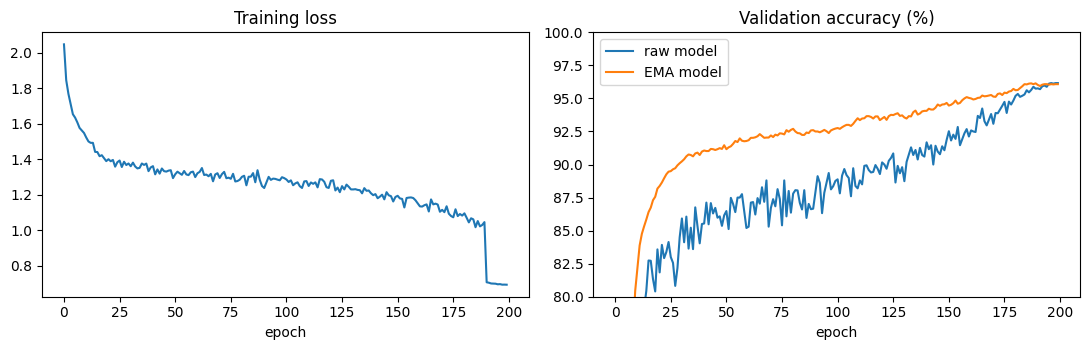

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(hist["loss"]); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["acc"], label="raw model"); ax[1].plot(hist["ema_acc"], label="EMA model")
ax[1].set_title("Validation accuracy (%)"); ax[1].set_xlabel("epoch"); ax[1].legend()
ax[1].set_ylim(80, 100); plt.tight_layout(); plt.savefig("curves.png", dpi=150); plt.show()

## 5. Final results

In [6]:
final = ema.module
print("=" * 60)
print(f"Number of trainable parameters      : {count_params(final):,}  (limit 5,000,000)")
print(f"Final validation accuracy (EMA)     : {val_acc(final):.2f}%")
print(f"Final validation accuracy (EMA+TTA) : {val_acc(final, tta=True):.2f}%")
print("=" * 60)

Number of trainable parameters      : 4,815,940  (limit 5,000,000)
Final validation accuracy (EMA)     : 96.08%
Final validation accuracy (EMA+TTA) : 96.48%


## 6. Kaggle submission

In [7]:
dl = DataLoader(ArrDS(x_test, np.zeros(len(x_test), int), test_tf), 512, num_workers=CFG["workers"])
pred = logits_of(final, dl, tta=True).argmax(1).numpy()
if classes is not None:                          # labels were class names
    pred = np.array(classes, dtype=object)[pred]
sub = sample.copy()                              # keeps the exact ID column and order
sub[sample.columns[1]] = pred
sub.to_csv("submission.csv", index=False)
print("Wrote submission.csv:", len(sub), "rows"); print(sub.head(3))

Wrote submission.csv: 2000 rows
   id  label
0   0      6
1   1      3
2   2      3


## References

- K. He et al., *Deep Residual Learning for Image Recognition*, CVPR 2016.
- S. Yun et al., *CutMix*, ICCV 2019.
- S. Muller and F. Hutter, *TrivialAugment*, ICCV 2021.
- L. Smith and N. Topin, *Super-Convergence* (OneCycle), 2018.
- C. Szegedy et al., *Rethinking the Inception Architecture* (label smoothing), CVPR 2016.
- PyTorch `torch.optim.swa_utils` (EMA).